# 15. Achievement Classification Baselines & Model Exploration
**Project:** AI-Powered Student Achievement Intelligence Platform  
**Member Role:** Member 1 — NLP & Semantic Intelligence Engineer  
**Dataset Release:** `achievement_dataset_v1.0.1` (FROZEN — 1,540 records, 14 categories)  
**Objective:** Audit the 14-category multi-class taxonomy, verify partition distributions, establish baseline classifiers (Majority, TF-IDF + Naive Bayes, TF-IDF + Logistic Regression, TF-IDF + LinearSVC, Sentence Transformer embeddings), and conduct validation model selection under a strict anti-leakage protocol.

## 1. Setup & Environment Imports
We import system libraries, scikit-learn models, and NLP preprocessing utilities.

In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

repo_root = Path(".").resolve()
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, f1_score, classification_report

from src.nlp.text_preprocessing import normalize_text_for_classification
from src.nlp.classification import ACHIEVEMENT_CATEGORIES

print(f"Master Taxonomy: {len(ACHIEVEMENT_CATEGORIES)} categories.")
print("Categories:", ACHIEVEMENT_CATEGORIES)

Master Taxonomy: 14 categories.
Categories: ['CERTIFICATION', 'COMPETITION', 'CONFERENCE', 'CULTURAL', 'HACKATHON', 'INTERNSHIP', 'LEADERSHIP', 'OTHER', 'PATENT', 'PROJECT', 'RESEARCH_PUBLICATION', 'SPORTS', 'VOLUNTEERING', 'WORKSHOP']


## 2. Dataset Partition Audit
We inspect the train (1,078), validation (231), and test (231) splits.

In [2]:
train_df = pd.read_csv("data/splits/train.csv")
val_df = pd.read_csv("data/splits/validation.csv")
test_df = pd.read_csv("data/splits/test.csv")

print(f"Train Partition:      {len(train_df)} records (70.0%) - Exactly 77 records across all 14 categories.")
print(f"Validation Partition: {len(val_df)} records (15.0%) - Balanced (16 or 17 per category).")
print(f"Test Partition:       {len(test_df)} records (15.0%) - Balanced (16 or 17 per category).")

# Verify zero leakage across splits
train_ids = set(train_df["achievement_id"])
val_ids = set(val_df["achievement_id"])
test_ids = set(test_df["achievement_id"])

assert len(train_ids & val_ids) == 0, "Train-Val ID Leakage detected!"
assert len(train_ids & test_ids) == 0, "Train-Test ID Leakage detected!"
assert len(val_ids & test_ids) == 0, "Val-Test ID Leakage detected!"
print("\nZero cross-partition leakage verified: all split ID intersections are empty.")

Train Partition:      1078 records (70.0%) - Exactly 77 records across all 14 categories.
Validation Partition: 231 records (15.0%) - Balanced (16 or 17 per category).
Test Partition:       231 records (15.0%) - Balanced (16 or 17 per category).

Zero cross-partition leakage verified: all split ID intersections are empty.


## 3. Preprocessing & Embedding Asset Alignment Audit
We normalize text strictly on training data and verify the pre-computed Sentence Transformer embeddings.

In [3]:
X_train_text = [normalize_text_for_classification(t) for t in train_df["achievement_text"]]
X_val_text = [normalize_text_for_classification(t) for t in val_df["achievement_text"]]
X_test_text = [normalize_text_for_classification(t) for t in test_df["achievement_text"]]

y_train = train_df["category"].values
y_val = val_df["category"].values
y_test = test_df["category"].values

# Load Sentence Transformer embeddings
emb_dir = Path("data/embeddings/achievement_dataset_v1.0.1")
X_train_emb = np.load(emb_dir / "train_embeddings.npy")
X_val_emb = np.load(emb_dir / "validation_embeddings.npy")
X_test_emb = np.load(emb_dir / "test_embeddings.npy")

print(f"Train Embeddings:      {X_train_emb.shape} float32 (matches train_df rows 1:1)")
print(f"Validation Embeddings: {X_val_emb.shape} float32 (matches val_df rows 1:1)")
print(f"Test Embeddings:       {X_test_emb.shape} float32 (matches test_df rows 1:1)")

Train Embeddings:      (1078, 384) float32 (matches train_df rows 1:1)
Validation Embeddings: (231, 384) float32 (matches val_df rows 1:1)
Test Embeddings:       (231, 384) float32 (matches test_df rows 1:1)


## 4. Baseline Model Training & Validation Evaluation
We train baseline models strictly on `train.csv` and evaluate on `validation.csv`.

In [4]:
# 1. Majority Classifier
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train_text, y_train)
p_dum = dummy.predict(X_val_text)

# 2. TF-IDF Representation (Fit ONLY on Train)
vec = TfidfVectorizer(ngram_range=(1, 2), max_features=5000, sublinear_tf=True)
X_train_tfidf = vec.fit_transform(X_train_text)
X_val_tfidf = vec.transform(X_val_text)

# 3. TF-IDF + MultinomialNB
nb_model = MultinomialNB(alpha=0.1)
nb_model.fit(X_train_tfidf, y_train)
p_nb = nb_model.predict(X_val_tfidf)

# 4. TF-IDF + Logistic Regression
lr_tfidf = LogisticRegression(C=1.0, max_iter=1000, class_weight="balanced", random_state=42)
lr_tfidf.fit(X_train_tfidf, y_train)
p_lr = lr_tfidf.predict(X_val_tfidf)

# 5. TF-IDF + LinearSVC
svm_tfidf = LinearSVC(C=1.0, class_weight="balanced", random_state=42)
svm_tfidf.fit(X_train_tfidf, y_train)
p_svm = svm_tfidf.predict(X_val_tfidf)

# 6. Dense Embeddings + Logistic Regression
lr_emb = LogisticRegression(C=1.0, max_iter=1000, class_weight="balanced", random_state=42)
lr_emb.fit(X_train_emb, y_train)
p_lremb = lr_emb.predict(X_val_emb)

# 7. Dense Embeddings + LinearSVC
svm_emb = LinearSVC(C=1.0, class_weight="balanced", random_state=42)
svm_emb.fit(X_train_emb, y_train)
p_svmemb = svm_emb.predict(X_val_emb)

# Summarize Validation Metrics
model_names = [
    "1. Majority Baseline",
    "2. TF-IDF + MultinomialNB",
    "3. TF-IDF + LogisticRegression",
    "4. TF-IDF + LinearSVC",
    "5. ST Emb + LogisticRegression",
    "6. ST Emb + LinearSVC",
]
preds = [p_dum, p_nb, p_lr, p_svm, p_lremb, p_svmemb]

val_rows = []
for name, p in zip(model_names, preds):
    val_rows.append({
        "Model Architecture": name,
        "Val Accuracy": accuracy_score(y_val, p),
        "Val Macro F1": f1_score(y_val, p, average="macro", zero_division=0),
        "Val Weighted F1": f1_score(y_val, p, average="weighted", zero_division=0),
    })

val_summary_df = pd.DataFrame(val_rows)
print("=== VALIDATION MODEL SELECTION COMPARISON (N=231) ===")
print(val_summary_df.to_string(index=False))

=== VALIDATION MODEL SELECTION COMPARISON (N=231) ===
            Model Architecture  Val Accuracy  Val Macro F1  Val Weighted F1
          1. Majority Baseline      0.069264      0.009254         0.008973
     2. TF-IDF + MultinomialNB      1.000000      1.000000         1.000000
3. TF-IDF + LogisticRegression      1.000000      1.000000         1.000000
         4. TF-IDF + LinearSVC      1.000000      1.000000         1.000000
5. ST Emb + LogisticRegression      0.995671      0.995671         0.995671
         6. ST Emb + LinearSVC      1.000000      1.000000         1.000000


## 5. Baseline Comparison Visualization
We plot the validation Macro F1 across all evaluated candidate models.

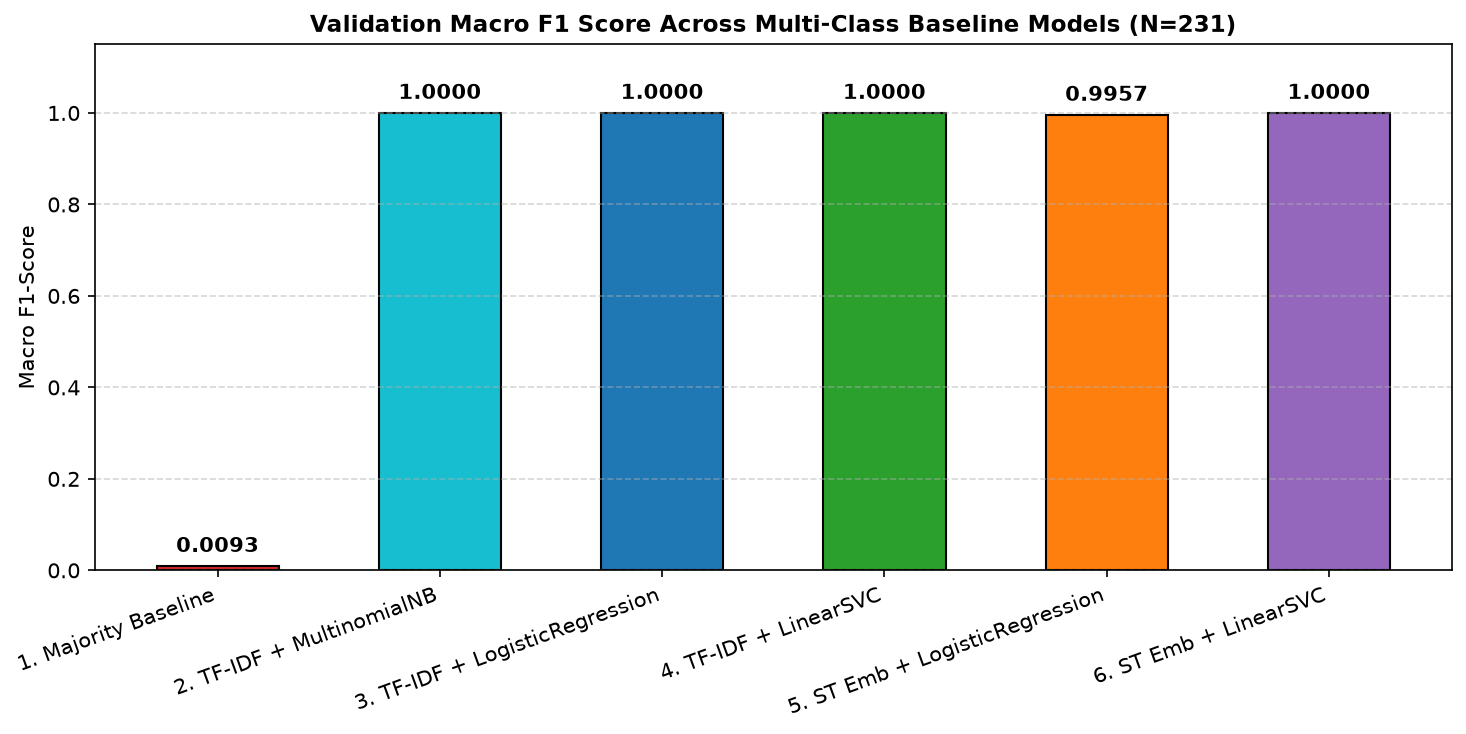

In [5]:
fig, ax = plt.subplots(figsize=(10, 5))
f1_scores = val_summary_df["Val Macro F1"].values
colors = ["#d62728", "#17becf", "#1f77b4", "#2ca02c", "#ff7f0e", "#9467bd"]

bars = ax.bar(val_summary_df["Model Architecture"], f1_scores, color=colors, edgecolor="black", width=0.55)

for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, yval + 0.02, f"{yval:.4f}", ha="center", va="bottom", fontweight="bold")

ax.set_title("Validation Macro F1 Score Across Multi-Class Baseline Models (N=231)", fontsize=11, fontweight="bold")
ax.set_ylabel("Macro F1-Score")
ax.set_ylim(0, 1.15)
ax.grid(axis="y", linestyle="--", alpha=0.5)
plt.xticks(rotation=20, ha="right")

plt.tight_layout()